# Исследовательский анализ продаж: от сырой выгрузки к выводам

**Ситуация.** Руководитель прислал выгрузку продаж за два года, склеенную из кабинетов Wildberries, Ozon и CRM сайта, и спрашивает: «Что у нас происходит с продажами и на что обратить внимание?»

**План.**
1. Загрузить выгрузку и оценить качество данных.
2. Очистить: служебные строки, дубли, типы, разное написание городов и каналов.
3. Сверить очищенные данные с эталоном, чтобы убедиться, что ничего не потеряно.
4. Исследовать динамику, сезонность, каналы, категории, возвраты и география.
5. Сформулировать выводы для руководителя.

> Данные синтетические, сгенерированы скриптом [`data/generate.py`](../../data/generate.py). Грязь в выгрузке (дубли, форматы дат, «1 234,00» вместо чисел, «СПб» и «г. Москва») воспроизводит то, что встречается в реальных выгрузках.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}".replace(",", " "))

# единый стиль графиков; цвета каналов закреплены и не меняются от графика к графику
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e3",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.edgecolor": "#9a9993", "figure.facecolor": "white",
})
CH_COLORS = {"Wildberries": "#2a78d6", "Ozon": "#eb6834", "Сайт": "#1baf7a"}
CAT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
rub = mticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f} млн")

## 1. Загрузка и первый взгляд

In [2]:
raw = pd.read_csv("../../data/raw_export.csv", sep=";", dtype=str, encoding="utf-8-sig")
print(f"Строк: {len(raw):,}, столбцов: {raw.shape[1]}".replace(",", " "))
raw.head()

Строк: 43 820  столбцов: 13


,order_id,order_date,channel,status,customer_id,city,sku,name,category,quantity,price,is_returned,promo_code
0,107188,15.07.2026,Wildberries,cancelled,4505,Казань,DU-0033,Френч-пресс,Посуда,1.0,3228,0,NaN
1,109435,2025-12-16,Ozon,delivered,5906,Москва,DU-0104,Корзина для белья,Ванная,1.0,"949,00",0,NaN
2,124399,18.03.2025,Wildberries,delivered,15384,Санкт-Петербург,DU-0079,Диффузор,Декор,1.0,"1 615,00",0,NaN
3,110440,2026-07-17,Сайт,cancelled,6548,Санкт-Петербург,DU-0079,Диффузор,Декор,1.0,"1 396,00",0,DOM15
4,102440,2026-06-12,WB,delivered,1520,Москва,DU-0025,Кружка керамическая,Посуда,2.0,3487,0,NaN


Читаю всё как строки (`dtype=str`): в выгрузке числа записаны по-разному, и автоопределение типов спрятало бы проблемы. Смотрю, что не так в каждом столбце.

In [3]:
def profile(df):
    return pd.DataFrame({
        "пропуски": df.isna().sum(),
        "уникальных": df.nunique(),
        "пример": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })
profile(raw)

,пропуски,уникальных,пример
order_id,0,24601,107188
order_date,2,1460,15.07.2026
channel,2,4,Wildberries
status,2,2,cancelled
customer_id,2,15500,4505
city,1365,20,Казань
sku,1,106,DU-0033
name,1,106,Френч-пресс
category,2,5,Посуда
quantity,1,4,1.0


In [4]:
print("Каналы:", raw.channel.value_counts(dropna=False).to_dict())
print("Статусы:", raw.status.value_counts(dropna=False).to_dict())
print("\nВарианты написания Москвы и Петербурга:")
print(raw.city[raw.city.str.contains("моск|спб|петер", case=False, na=False)].value_counts().to_string())
print("\nФорматы дат:", raw.order_date.str.replace(r"\d", "9", regex=True).value_counts().to_dict())
print("\nЦены с пробелами и запятой:", raw.price.str.contains(r"[ ,]", na=False).sum())
print("Полных дублей строк:", raw.duplicated().sum())
raw[~raw.order_id.str.fullmatch(r"\d{6}", na=False)]

Каналы: {'Ozon': 14122, 'WB': 10099, 'Wildberries': 10046, 'Сайт': 9551, nan: 2}
Статусы: {'delivered': 41461, 'cancelled': 2357, nan: 2}

Варианты написания Москвы и Петербурга:
city
Москва             9212
Санкт-Петербург    4538
г. Москва           948
Москва              926
москва              883
спб                 477
Санкт Петербург     469
СПб                 452

Форматы дат: {'9999-99-99': 28609, '99.99.9999': 15209}

Цены с пробелами и запятой: 17717
Полных дублей строк: 648


,order_id,order_date,channel,status,customer_id,city,sku,name,category,quantity,price,is_returned,promo_code
43818,ИТОГО,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"48 512 333,00",NaN,NaN
43819,0,NaN,NaN,NaN,NaN,NaN,TEST,тестовый заказ,NaN,-1.0,0,NaN,NaN


**Найденные проблемы:**
- строка «ИТОГО» из Excel и тестовый заказ с нулевой ценой и количеством −1;
- полные дубли строк: так бывает, когда отчёты за пересекающиеся периоды склеили дважды;
- канал записан и как «WB», и как «Wildberries»;
- даты в двух форматах: `2025-12-16` и `15.07.2026`;
- цены строкой: `949,00` и `3 228,00`;
- один город записан по-разному: «Москва», «москва», «г. Москва», «Москва » с пробелом;
- пропуски в городе.

## 2. Очистка

Каждый шаг записываю в журнал: сколько строк было и стало. Такой журнал можно показать заказчику, если он спросит, куда делись данные.

In [5]:
log = []
def step(name, df_before, df_after):
    log.append({"шаг": name, "было": len(df_before), "стало": len(df_after), "удалено": len(df_before) - len(df_after)})
    return df_after

df = raw.copy()
df = step("служебные и тестовые строки", df, df[df.order_id.str.fullmatch(r"\d{6}", na=False)])
df = step("полные дубли", df, df.drop_duplicates())

# типы
# два формата дат разбираю явно: «умный» format="mixed" путает день и месяц в датах вроде 2025-03-04
iso = pd.to_datetime(df.order_date, format="%Y-%m-%d", errors="coerce")
ru = pd.to_datetime(df.order_date, format="%d.%m.%Y", errors="coerce")
df["order_date"] = iso.fillna(ru)
assert df.order_date.notna().all(), "остались нераспознанные даты"
df["price"] = df.price.str.replace(r"\s", "", regex=True).str.replace(",", ".").astype(float)
df["quantity"] = df.quantity.astype(float).astype(int)
df[["order_id", "customer_id", "is_returned"]] = df[["order_id", "customer_id", "is_returned"]].astype(float).astype(int)

# справочники
df["channel"] = df.channel.replace({"WB": "Wildberries"})
city_map = {"москва": "Москва", "г. москва": "Москва", "спб": "Санкт-Петербург", "санкт петербург": "Санкт-Петербург"}
df["city"] = df.city.str.strip().map(lambda c: city_map.get(c.lower(), c) if isinstance(c, str) else c)
df["city"] = df.city.fillna("не указан")

df = step("некорректные количество или цена", df, df[(df.quantity > 0) & (df.price > 0)])
pd.DataFrame(log)

,шаг,было,стало,удалено
0,служебные и тестовые строки,43820,43818,2
1,полные дубли,43818,43170,648
2,некорректные количество или цена,43170,43170,0


In [6]:
assert df.order_date.between("2024-10-01", "2026-09-30").all(), "даты вне периода"
assert df.channel.isin(["Wildberries", "Ozon", "Сайт"]).all()
assert not df.duplicated(["order_id", "sku"]).any(), "одна позиция заказа встречается дважды"
print("Города после очистки:", df.city.nunique(), "→", sorted(df.city.unique())[:6], "…")
df.dtypes

Города после очистки: 15 → ['Воронеж', 'Екатеринбург', 'Казань', 'Краснодар', 'Москва', 'Нижний Новгород'] …


order_id                int64
order_date     datetime64[us]
channel                   str
status                    str
customer_id             int64
city                      str
sku                       str
name                      str
category                  str
quantity                int64
price                 float64
is_returned             int64
promo_code                str
dtype: object

## 3. Сверка с эталоном

Проверяю, что очистка не потеряла и не задвоила продажи: сравниваю число позиций и выручку с эталонными таблицами базы. В рабочей задаче эталоном была бы сумма из бухгалтерии или итог кабинета маркетплейса.

In [7]:
ref_items = pd.read_csv("../../data/order_items.csv")
check = pd.DataFrame({
    "очищенная выгрузка": [len(df), (df.price * df.quantity).sum()],
    "эталон": [len(ref_items), (ref_items.price * ref_items.quantity).sum()],
}, index=["позиций", "сумма, ₽"])
check["расхождение"] = check["очищенная выгрузка"] - check["эталон"]
check

,очищенная выгрузка,эталон,расхождение
позиций,43 170.0,43 170.0,0.0
"сумма, ₽",110 752 907.0,110 752 907.0,0.0


Расхождение нулевое: очистка корректна. Дальше работаю с доставленными заказами и считаю **чистую выручку**, то есть без возвращённых позиций.

In [8]:
df["revenue"] = df.price * df.quantity
df["net"] = df.revenue * (1 - df.is_returned)
sales = df[df.status == "delivered"].copy()
sales["month"] = sales.order_date.dt.to_period("M").dt.to_timestamp()
orders = (sales.groupby(["order_id", "order_date", "month", "channel", "customer_id", "city"], as_index=False)
               .agg(net=("net", "sum"), items=("quantity", "sum")))
print(f"Доставленных заказов: {len(orders):,}; отменено: {df[df.status=='cancelled'].order_id.nunique():,} "
      f"({df[df.status=='cancelled'].order_id.nunique() / df.order_id.nunique():.1%})".replace(",", " "))

Доставленных заказов: 24 187; отменено: 1 343 (5.5%)


## 4. Исследование
### 4.1. Динамика выручки по каналам

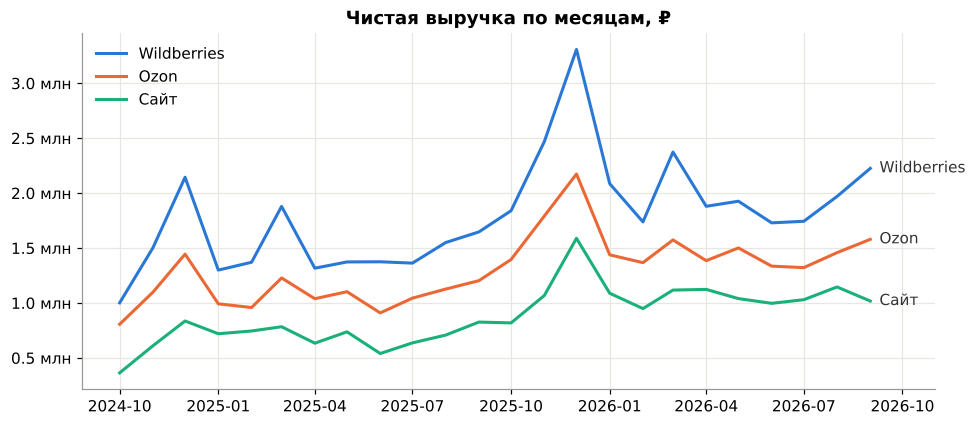

month,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
channel,,,,,,,,
Wildberries,47.1,45.3,45.2,45.1,46.2,45.0,42.8,43.9
Ozon,34.7,31.9,33.8,33.4,32.9,32.0,32.7,32.3
Сайт,18.2,22.8,21.1,21.4,20.9,23.0,24.5,23.8


In [9]:
m = sales.pivot_table(index="month", columns="channel", values="net", aggfunc="sum")[list(CH_COLORS)]
fig, ax = plt.subplots(figsize=(10, 4.2))
for ch in m.columns:
    ax.plot(m.index, m[ch], color=CH_COLORS[ch], lw=2, label=ch)
    ax.annotate(ch, (m.index[-1], m[ch].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", color="#333")
ax.yaxis.set_major_formatter(rub)
ax.set_title("Чистая выручка по месяцам, ₽")
ax.legend(loc="upper left", frameon=False)
ax.set_xlim(right=m.index[-1] + pd.Timedelta(days=60))
plt.show()

share = (m.div(m.sum(axis=1), axis=0) * 100).resample("QS").mean().round(1)
share.index = share.index.to_period("Q").astype(str)
share.T

### 4.2. Сезонность: в какие месяцы и дни продают больше

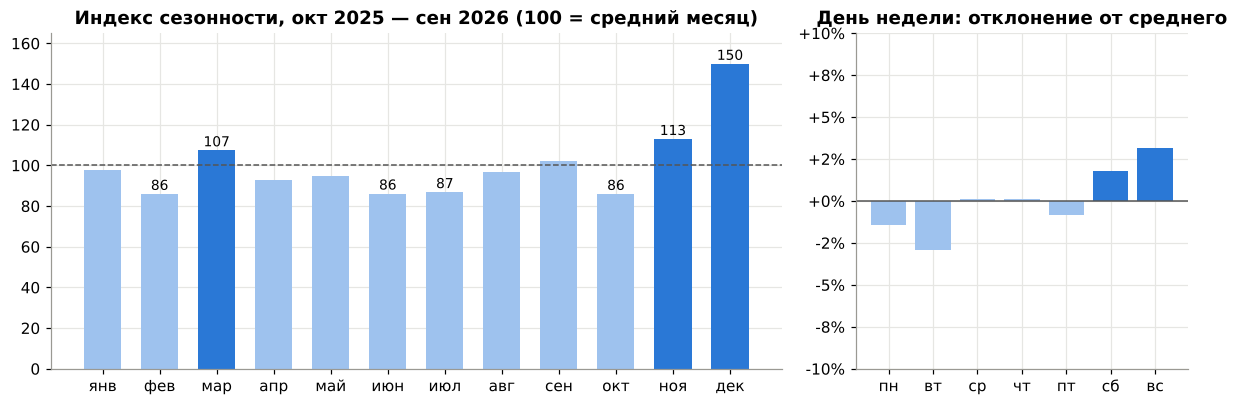

In [10]:
# индекс сезонности считаю по второму году: в первом (окт 2024 — сен 2025) магазин только набирал базу,
# и низкий старт исказил бы картину
y2 = sales[sales.order_date >= "2025-10-01"]
season = y2.groupby(y2.order_date.dt.month).net.sum()
season = season / season.mean() * 100           # 100 = средний месяц года
wd = sales.groupby(sales.order_date.dt.dayofweek).net.sum()
wd = wd / wd.mean() * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
months = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
cols = ["#2a78d6" if v >= 105 else "#9ec2ee" for v in season]
a1.bar(range(12), season, 0.65, color=cols)
for x_, v in enumerate(season):
    if v >= 105 or v <= 88:
        a1.text(x_, v + 2, f"{v:.0f}", ha="center", fontsize=9)
a1.axhline(100, color="#555", lw=1, ls="--")
a1.set_xticks(range(12), months); a1.set_ylim(0, 165)
a1.set_title("Индекс сезонности, окт 2025 — сен 2026 (100 = средний месяц)")
a2.bar(range(7), wd - 100, color=["#9ec2ee"] * 5 + ["#2a78d6"] * 2)
a2.axhline(0, color="#555", lw=1)
a2.set_xticks(range(7), ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]); a2.set_ylim(-10, 10)
a2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
a2.set_title("День недели: отклонение от среднего")
plt.tight_layout(); plt.show()

Декабрь в 1,5 раза выше среднего месяца, ноябрь — на 13% выше, март выделяется из-за 8 Марта (+7%). Провалы — февраль, лето и октябрь: 86–87% от среднего. Дни недели почти не влияют: выходные дают всего на 2–3% больше будней, поэтому планировать нагрузку по дням недели смысла нет, а по месяцам — есть.

### 4.3. Средний чек и что его определяет

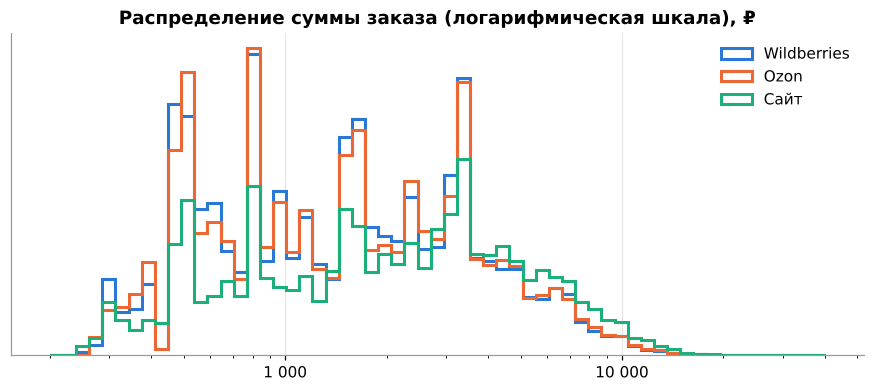

,заказов,средний_чек,медиана,товаров_в_заказе
channel,,,,
Сайт,4309,4 903.0,4 256.0,2.6
Ozon,8164,3 831.0,3 289.0,2.0
Wildberries,11714,3 680.4,3 211.5,2.0


In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(np.log10(200), np.log10(40000), 60)
for ch in CH_COLORS:
    ax.hist(orders.loc[orders.channel == ch, "net"].clip(lower=200), bins=bins, histtype="step", lw=2, color=CH_COLORS[ch], label=ch, density=True)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_title("Распределение суммы заказа (логарифмическая шкала), ₽")
ax.legend(frameon=False); ax.set_yticks([])
plt.show()

orders.groupby("channel").agg(
    заказов=("order_id", "size"),
    средний_чек=("net", "mean"),
    медиана=("net", "median"),
    товаров_в_заказе=("items", "mean"),
).round(1).sort_values("средний_чек", ascending=False)

Распределение суммы заказа сильно скошено вправо: несколько дорогих заказов тянут среднее вверх, поэтому рядом со средним показываю медиану. На сайте чек выше за счёт количества товаров в заказе: там чаще берут несколько позиций (корзина, рекомендации, бесплатная доставка от порога).

### 4.4. Категории: выручка, маржа и возвраты

In [12]:
prod = pd.read_csv("../../data/products.csv")[["sku", "cost_price"]]
ch_cost = pd.read_csv("../../data/channels.csv").set_index("channel")
s = sales.merge(prod, on="sku")
s["profit"] = (s.net * (1 - s.channel.map(ch_cost.commission_rate))
               - s.cost_price * s.quantity * (1 - s.is_returned)
               - s.channel.map(ch_cost.logistics_per_item) * s.quantity * (1 + s.is_returned))
cat = s.groupby("category").agg(выручка=("net", "sum"), прибыль_до_рекламы=("profit", "sum"),
                                возвраты=("is_returned", "mean")).sort_values("выручка", ascending=False)
cat["маржа_%"] = cat.прибыль_до_рекламы / cat.выручка * 100
cat["возвраты"] *= 100
cat["доля_выручки_%"] = cat.выручка / cat.выручка.sum() * 100
cat.rename(columns={"возвраты": "возвраты_%"}).round(1)

,выручка,прибыль_до_рекламы,возвраты_%,маржа_%,доля_выручки_%
category,,,,,
Посуда,37 965 406.0,13 353 595.7,6.9,35.2,39.7
Текстиль,20 558 802.0,7 699 807.3,14.4,37.5,21.5
Ванная,16 982 511.0,6 309 593.7,8.6,37.2,17.8
Декор,15 825 011.0,5 242 711.2,7.7,33.1,16.6
Хранение,4 183 865.0,1 272 150.1,5.2,30.4,4.4


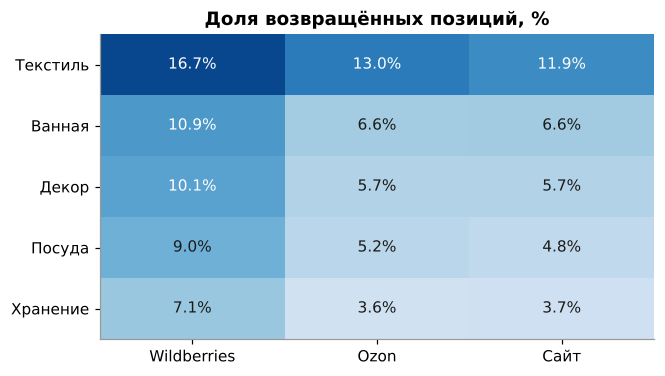

In [13]:
heat = s.pivot_table(index="category", columns="channel", values="is_returned", aggfunc="mean")[list(CH_COLORS)] * 100
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=heat.values.max() * 1.1, aspect="auto")
ax.set_xticks(range(3), heat.columns); ax.set_yticks(range(len(heat)), heat.index)
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", color="white" if v > heat.values.max() * 0.6 else "#1a1a19")
ax.set_title("Доля возвращённых позиций, %")
plt.show()

Посуда даёт 40% выручки при умеренных возвратах. Текстиль — вторая категория по выручке (21%) и лидер по возвратам (14%), особенно на Wildberries: почти каждая шестая позиция возвращается. Возвраты на WB выше во всех категориях: покупатели маркетплейса чаще заказывают «на примерку» и отказываются при получении.

### 4.5. География

Москва и Петербург вместе: 41.1% выручки
Город не указан: 3.2% выручки


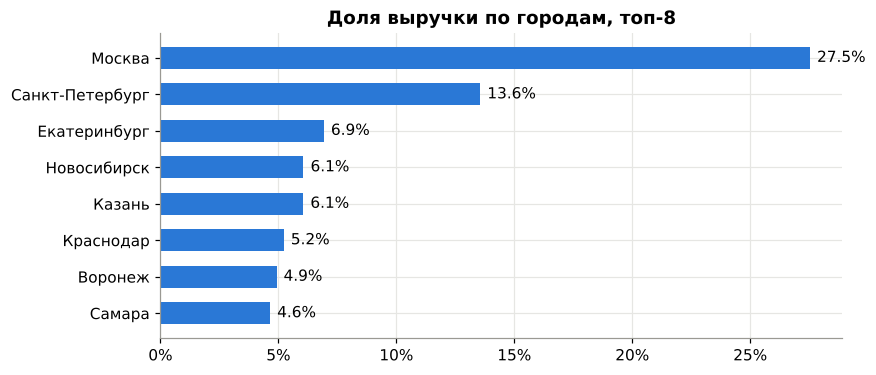

In [14]:
geo = orders.groupby("city").agg(заказов=("order_id", "size"), выручка=("net", "sum"), чек=("net", "mean"))
geo["доля_%"] = geo.выручка / geo.выручка.sum() * 100
geo = geo.sort_values("выручка", ascending=False)
top = geo.head(8)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(top.index[::-1], top["доля_%"][::-1], color="#2a78d6", height=0.6)
for y, v in enumerate(top["доля_%"][::-1]):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center")
ax.set_title("Доля выручки по городам, топ-8"); ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
plt.show()
print(f"Москва и Петербург вместе: {geo.loc[['Москва', 'Санкт-Петербург'], 'доля_%'].sum():.1f}% выручки")
print(f"Город не указан: {geo.loc['не указан', 'доля_%']:.1f}% выручки")

### 4.6. Новые и повторные покупатели

Доля выручки от повторных заказов:
month
2024Q4   18.4
2025Q1   38.6
2025Q2   41.0
2025Q3   38.7
2025Q4   32.2
2026Q1   43.2
2026Q2   44.9
2026Q3   39.9
Freq: Q-DEC


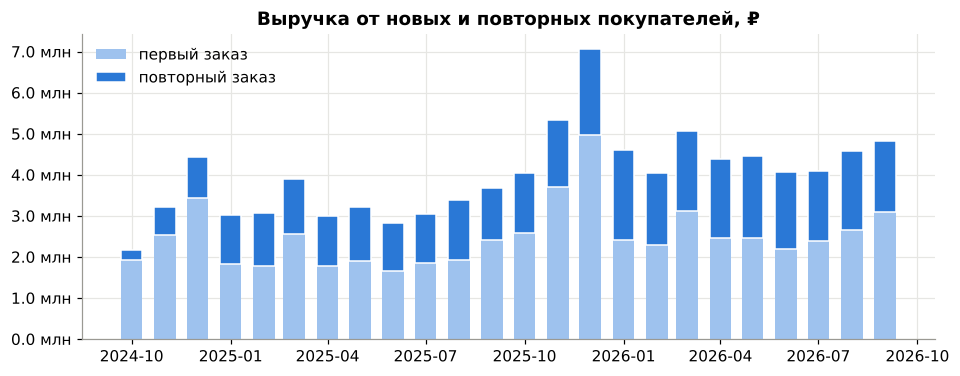

In [15]:
orders = orders.sort_values(["order_date", "order_id"])
orders["is_repeat"] = orders.duplicated("customer_id")
rep = orders.groupby(["month", "is_repeat"]).net.sum().unstack().rename(columns={False: "новые", True: "повторные"})
rep_share = rep["повторные"] / rep.sum(axis=1) * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(rep.index, rep["новые"], width=20, color="#9ec2ee", label="первый заказ")
ax.bar(rep.index, rep["повторные"], width=20, bottom=rep["новые"], color="#2a78d6", label="повторный заказ",
       edgecolor="white", linewidth=1)
ax.yaxis.set_major_formatter(rub); ax.legend(frameon=False, loc="upper left")
ax.set_title("Выручка от новых и повторных покупателей, ₽")
plt.show()
print("Доля выручки от повторных заказов:")
print(rep_share.resample("QS").mean().round(1).rename(lambda d: d.to_period("Q")).to_string())

В первом квартале у магазина ещё не было базы, и повторные заказы давали 18% выручки. С 2025 года их доля держится на 38–45% и не растёт; в IV квартале она проседает, потому что праздники приводят много новых покупателей. Повторные покупки растут только вместе с базой, удержанием системно не занимаются.

## 5. Выводы для руководителя

| Что видно | Что это значит | Что сделать |
|---|---|---|
| Выручка растёт во всех каналах, доля сайта выросла с 18% до 24% | Рост здоровый, не зависит от одной площадки | Продолжать развивать сайт как самый маржинальный канал |
| Декабрь в 1,5 раза выше среднего месяца, февраль, лето и октябрь — на 13–14% ниже | Пик предсказуем, к нему можно подготовиться | Запасы группы A на склады маркетплейсов к 1 декабря; летом — акции на сайте |
| Чек на сайте выше за счёт числа товаров в заказе | Корзина и допродажи работают | Добавить «с этим покупают» в карточки на маркетплейсах (комплекты) |
| Текстиль: 21% выручки и 14% возвратов, на WB — 17% | Каждый возврат — двойная логистика и риск брака | Переделать карточки текстиля: размеры, фото цвета при дневном свете, состав |
| Москва и Петербург дают 41% выручки | Зависимость от двух городов, но и потенциал регионов | Проверить доставку в регионы: склады маркетплейсов ближе к покупателям |
| Доля выручки от повторных заказов не растёт с 2025 года (~40%) | Удержанием не занимаются | Триггерные письма через 30–40 дней после покупки, реактивация уходящих |

**Что дальше:** проверить гипотезы о карточках текстиля и о рассылках A/B-тестом. Пример такого теста — в [проекте A/B-теста](../ab-test/). SQL-версия анализа каналов и когорт — в [SQL-проекте](../sql-marketplace/).